# Algoritmo de Shor

In [2]:
import numpy as np
from qiskit import QuantumCircuit,  transpile, assemble
from qiskit.visualization import plot_histogram
from qiskit_aer.aerprovider import AerSimulator
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt

Objetivo:

Fatorar o número 15 encontrando a ordem $r$ de um número $a$ tal que:
\begin{equation}
a^r \text{mod}(N)=1
\end{equation}

Escolhemos $a = 2$, que é coprimo de 15.

SWAP dentro de c_amod15(a, power)

Essas portas não fazem parte da QFT, mas sim da implementação da exponenciação modular $a^x \text{mod} \, N$, no caso com $N=15$.

$\rightarrow$ Cada um dos 4 qubits do registrador de trabalho representa um número binário de 0 a 15.

$\rightarrow$ A operação $a^k mod 15$ pode ser vista como uma permutação dos estados. Os SWAP são usados para trocar os qubits de posição e assim representar corretamente o resultado da multiplicação modular.

$\rightarrow$ Por exemplo, para $a=2$, multiplicar por 2 módulo 15 desloca os estados, algo que pode ser implementado com:

\begin{align}
swap(0,1) \\
swap(1,2) \\
swap(2,3) \\
\end{align}
Isso move o conteúdo do qubit menos significativo para o mais significativo, simulando a multiplicação.    



Portanto, esses SWAP implementam a operação aritmética $U_{\omega}$ no espaço de estados binário.

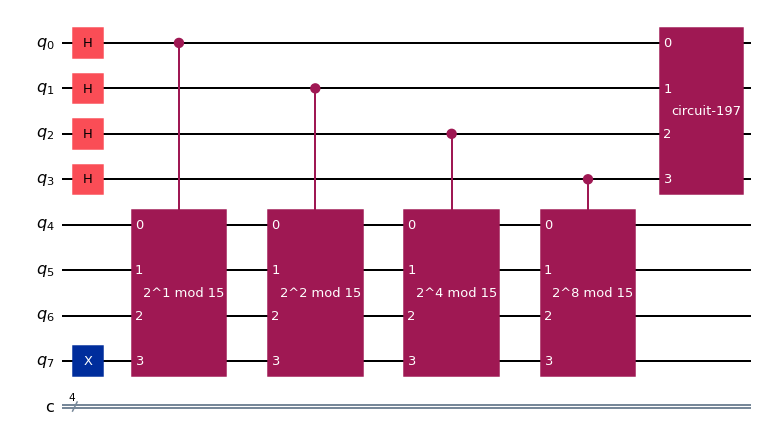

In [3]:
# Parâmetros
N = 15      # Número para fatorar
a = 2       # Número aleatório tal que mdc(a, N) = 1

n_count = 4  # Qubits para contagem de registros (precisão)

# Exponenciação modular: a^x mod N
def c_amod15(a, power):
    U = QuantumCircuit(4)  # 4 qubits para representar estados de 0 a 15

    for _ in range(power % 4):  # Como a^4 mod 15 = 1, usamos periodicidade
        if a == 2:
            U.swap(0, 1)
            U.swap(1, 2)
            U.swap(2, 3)
        elif a == 7:
            U.swap(2, 3)
            U.swap(1, 2)
            U.swap(0, 1)
        elif a == 8:
            U.swap(0, 3)
            U.swap(1, 2)
        elif a == 11:
            U.swap(1, 3)
            U.swap(0, 2)
        elif a == 13:
            U.swap(0, 1)
            U.swap(1, 3)
            U.swap(3, 2)
        elif a == 4:
            U.swap(0, 2)
            U.swap(1, 3)
        else:
            raise ValueError("a não suportado")

    U = U.to_gate()
    U.name = f"{a}^{power} mod 15"
    c_U = U.control()
    return c_U

# Estimativa da fase de a^x mod N
qc = QuantumCircuit(n_count + 4, n_count)  # 4 qubits para U, n_count para QPE

# Inicio com superposição
for q in range(n_count):
    qc.h(q)

# Estado inicial: |1⟩ para o registrador da função
qc.x(n_count + 3)  # Último qubit de U

# Aplicamos U^2^j na ordem inversa
for q in range(n_count):
    c_U = c_amod15(a, 2 ** q)
    qc.append(c_U, [q] + [i + n_count for i in range(4)])

# Aplicamos a QFT inversa
def qft_dagger(n):
    qc = QuantumCircuit(n)
    for qubit in range(n//2):
        qc.swap(qubit, n - qubit - 1)
    for j in range(n):
        for m in range(j):
            qc.cp(-np.pi/float(2**(j-m)), m, j)
        qc.h(j)
    return qc

qft_inv = qft_dagger(n_count)
qc.append(qft_inv.to_gate(), range(n_count))


# Circuito
qc.draw('mpl')

## Vetor estado

In [4]:
psi = Statevector(qc)
psi.draw(output = "latex")

<IPython.core.display.Latex object>

## Simulação

In [5]:
from qiskit_aer.aerprovider import AerSimulator

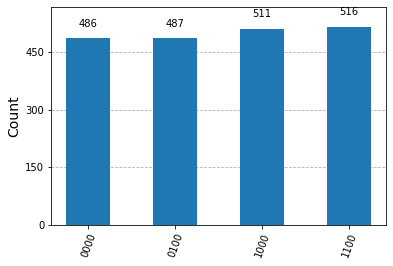

In [6]:
qc.measure(range(n_count), range(n_count))

simulator1 = AerSimulator()
tqc = transpile(qc, simulator1)

result1 = simulator1.run(tqc, shots = 2000).result()
counts1 = result1.get_counts(tqc)
plot_histogram(counts1)

## Obtenção dos fatores

In [7]:
from fractions import Fraction
import math

Etapa 1: Extrair a fase $\phi = s/2^n$.

Após simular o circuito, você obtém uma sequência de bits medida, como '0100', que corresponde a um número decimal s. Isso é interpretado como:
\begin{equation}
\phi \approx \frac{s}{2^n}.
\end{equation}

Etapa 2: Aproxime $\phi$ como uma fração $k/r$

Usamos frações contínuas (Fraction de Python) para encontrar uma fração k/r que se aproxime bastante de $\phi$, onde $r$ é uma ordem possível.

Etapa 3: Teste se $a^r \text{mod}(N) = 1$ e obtenha os fatores

Em caso afirmativo, use:
\begin{equation}    
mdc⁡(a^{r/2} \pm 1,N)
\end{equation}
para obter os fatores de $N$.

## Parte clássica

In [8]:
# Considere os N resultados mais frequentes
from collections import Counter

# Ordenamos as medições por frequência
top_measurements = Counter(counts1).most_common(5)

for measured, freq in top_measurements:
    print(f"\nTeste de medição: {measured} ({freq} vezes)")
    s = int(measured, 2)
    phi = s / 2**n_count
    frac = Fraction(phi).limit_denominator(N)
    r = frac.denominator

    print(f"Fase estimada: {phi}, fração: {frac}, r = {r}")

    if r % 2 != 0:
        print("r é ímpar, é descartado.")
        continue
    if pow(a, r, N) != 1:
        print(f"{a}^{r} mod {N} ≠ 1, é descartado.")
        continue

    # Verificamos os fatores
    plus = math.gcd(pow(a, r//2) + 1, N)
    minus = math.gcd(pow(a, r//2) - 1, N)

    if 1 < plus < N:
        print(f" !!! Fator encontrado: {plus}")
    if 1 < minus < N:
        print(f" !!! Fator encontrado: {minus}")


Teste de medição: 1100 (516 vezes)
Fase estimada: 0.75, fração: 3/4, r = 4
 !!! Fator encontrado: 5
 !!! Fator encontrado: 3

Teste de medição: 1000 (511 vezes)
Fase estimada: 0.5, fração: 1/2, r = 2
2^2 mod 15 ≠ 1, é descartado.

Teste de medição: 0100 (487 vezes)
Fase estimada: 0.25, fração: 1/4, r = 4
 !!! Fator encontrado: 5
 !!! Fator encontrado: 3

Teste de medição: 0000 (486 vezes)
Fase estimada: 0.0, fração: 0, r = 1
r é ímpar, é descartado.
